# LAB 08 — Pretrained Transformers và BERT Fine-Tuning

Bài toán: phân loại cảm xúc IMDb. Notebook dùng BERT nhỏ đã pretrain để các experiment có thể chạy trên CPU; model from-scratch dùng cùng kiến trúc và tokenizer. Mỗi lượt train chạy 1 epoch để giữ các so sánh trong mức tính toán vừa phải. Chạy cell từ trên xuống dưới.

## 1. Imports, đường dẫn và cấu hình

In [1]:
from pathlib import Path
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
import gc
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import confusion_matrix
from transformers import logging as transformers_logging

PROJECT_DIR = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / 'data' / 'IMDB Dataset.csv').exists()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Không tìm thấy data/IMDB Dataset.csv.')
LAB_DIR = PROJECT_DIR / 'lab08'
sys.path.insert(0, str(LAB_DIR))
from pretrained_classification import (
    MODEL_NAME, RANDOM_SEED, build_model, encode_texts, evaluate_model,
    find_project_dir, freeze_encoder, load_imdb, load_tokenizer, make_loader,
    parameter_counts, set_seed, split_imdb, stratified_nested_subsets, train_model,
)

transformers_logging.set_verbosity_error()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MAX_TOKEN_LENGTH = 256
BASE_MAX_LENGTH = 128
BATCH_SIZE = 128
EPOCHS = 1
LEARNING_RATE = 2e-5
set_seed(RANDOM_SEED)
torch.set_num_threads(1)
torch.set_num_interop_threads(1)
print('Project:', PROJECT_DIR)
print('Model:', MODEL_NAME)
print('Device:', DEVICE)
print('Batch size:', BATCH_SIZE, '| epochs:', EPOCHS, '| learning rate:', LEARNING_RATE)

C:\Users\KIEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: C:\Users\KIEN\OneDrive\Máy tính\NLP
Model: google/bert_uncased_L-2_H-128_A-2
Device: cpu
Batch size: 128 | epochs: 1 | learning rate: 2e-05


## 2. Đọc và làm sạch IMDb

In [2]:
DATA_PATH = PROJECT_DIR / 'data' / 'IMDB Dataset.csv'
data, cleaning_stats = load_imdb(DATA_PATH)
display(pd.DataFrame([cleaning_stats]))
display(data['sentiment'].value_counts().rename_axis('sentiment').to_frame('reviews'))
print('Số review sau làm sạch:', len(data))

,raw_rows,rows_after_cleaning,missing_rows_removed,conflicting_rows_removed,duplicate_rows_removed
0,50000,49578,0,0,422


,reviews
sentiment,
positive,24882
negative,24696


Số review sau làm sạch: 49578


## 3. Tạo train / validation / test split

In [3]:
train_df, validation_df, test_df = split_imdb(data, seed=RANDOM_SEED)
SPLIT_TABLE = pd.DataFrame([
    {'split': 'train', 'rows': len(train_df), 'positive_rate': train_df.label_id.mean()},
    {'split': 'validation', 'rows': len(validation_df), 'positive_rate': validation_df.label_id.mean()},
    {'split': 'test', 'rows': len(test_df), 'positive_rate': test_df.label_id.mean()},
])
display(SPLIT_TABLE)
y_train = train_df['label_id'].to_numpy()
y_validation = validation_df['label_id'].to_numpy()
y_test = test_df['label_id'].to_numpy()

,split,rows,positive_rate
0,train,29746,0.501849
1,validation,9916,0.501916
2,test,9916,0.501916


## 4. Nạp tokenizer và kiểm tra một câu

In [4]:
tokenizer = load_tokenizer(MODEL_NAME)
example_text = 'The cats are playing.'
example_tokens = tokenizer.tokenize(example_text)
example_encoded = tokenizer(example_text)
print('Keys:', list(example_encoded.keys()))
print('Tokens:', tokenizer.convert_ids_to_tokens(example_encoded['input_ids']))
print('Token IDs:', example_encoded['input_ids'])
print('Attention mask:', example_encoded['attention_mask'])
print('Words:', len(example_text.split()), '| subword tokens:', len(example_tokens))

Keys: ['input_ids', 'token_type_ids', 'attention_mask']
Tokens: ['[CLS]', 'the', 'cats', 'are', 'playing', '.', '[SEP]']
Token IDs: [101, 1996, 8870, 2024, 2652, 1012, 102]
Attention mask: [1, 1, 1, 1, 1, 1, 1]
Words: 4 | subword tokens: 5


## 5. Tokenize dữ liệu cho các độ dài sequence

In [5]:
train_encodings = encode_texts(tokenizer, train_df['review'], MAX_TOKEN_LENGTH)
validation_encodings = encode_texts(tokenizer, validation_df['review'], MAX_TOKEN_LENGTH)
test_encodings = encode_texts(tokenizer, test_df['review'], MAX_TOKEN_LENGTH)
print('Train input_ids:', tuple(train_encodings['input_ids'].shape))
print('Validation input_ids:', tuple(validation_encodings['input_ids'].shape))
print('Test input_ids:', tuple(test_encodings['input_ids'].shape))

Train input_ids: (29746, 256)
Validation input_ids: (9916, 256)
Test input_ids: (9916, 256)


## 6. Hàm tạo loader, huấn luyện và ghi kết quả

In [6]:
RESULT_ROWS = []

def make_split_loaders(max_length, batch_size=BATCH_SIZE, train_encodings_override=None, labels_override=None):
    source_encodings = train_encodings if train_encodings_override is None else train_encodings_override
    source_labels = y_train if labels_override is None else labels_override
    train_loader = make_loader(source_encodings, source_labels, max_length, batch_size, shuffle=True)
    validation_loader = make_loader(validation_encodings, y_validation, max_length, batch_size, shuffle=False)
    test_loader = make_loader(test_encodings, y_test, max_length, batch_size, shuffle=False)
    return train_loader, validation_loader, test_loader

def record_result(experiment, model_name, split_name, evaluation, run, max_length, train_fraction=1.0):
    metrics = evaluation['metrics']
    row = {
        'experiment': experiment, 'model': model_name, 'split': split_name,
        'train_fraction': train_fraction, 'max_length': max_length,
        'accuracy': metrics['accuracy'], 'precision': metrics['precision'],
        'recall': metrics['recall'], 'f1': metrics['f1'],
        'f1_macro': metrics['f1_macro'], 'loss': metrics['loss'],
        'training_time_seconds': run['training_seconds'],
        'parameters': run['parameters'], 'trainable_parameters': run['trainable_parameters'],
        'peak_process_rss_mb': run['peak_rss_mb'],
        'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
    }
    RESULT_ROWS.append(row)
    return row

def train_one_model(pretrained, max_length=BASE_MAX_LENGTH, train_encodings_override=None, labels_override=None, batch_size=BATCH_SIZE, frozen=False):
    set_seed(RANDOM_SEED)
    model = build_model(MODEL_NAME, pretrained=pretrained)
    if frozen:
        freeze_encoder(model)
    train_loader, validation_loader, test_loader = make_split_loaders(
        max_length, batch_size, train_encodings_override, labels_override
    )
    run = train_model(
        model, train_loader, validation_loader, DEVICE,
        epochs=EPOCHS, learning_rate=LEARNING_RATE,
    )
    run['validation_result'] = evaluate_model(run['model'], validation_loader, DEVICE)
    run['test_result'] = evaluate_model(run['model'], test_loader, DEVICE)
    return run

print('Các hàm huấn luyện đã sẵn sàng.')

Các hàm huấn luyện đã sẵn sàng.


## 7. Experiment 1 — Pretrained so với train from scratch

Cùng kiến trúc, tokenizer, split, độ dài 128, batch size, optimizer và số epoch. Classification head được khởi tạo mới ở cả hai model.

In [7]:
scratch_run = train_one_model(pretrained=False, max_length=BASE_MAX_LENGTH)
scratch_summary = {
    'metrics': scratch_run['test_result']['metrics'],
    'training_time_seconds': scratch_run['training_seconds'],
    'parameters': scratch_run['parameters'],
}
record_result('Experiment 1 - Scratch vs pretrained', 'BERT from scratch', 'test', scratch_run['test_result'], scratch_run, BASE_MAX_LENGTH)
del scratch_run
_ = gc.collect()

after_pretrained = train_one_model(pretrained=True, max_length=BASE_MAX_LENGTH)
fine_tuned_run = after_pretrained
record_result('Experiment 1 - Scratch vs pretrained', 'BERT fine-tuned', 'test', fine_tuned_run['test_result'], fine_tuned_run, BASE_MAX_LENGTH)

comparison_1 = pd.DataFrame([
    {'model': 'BERT from scratch', **scratch_summary['metrics'], 'training_time_seconds': scratch_summary['training_time_seconds'], 'parameters': scratch_summary['parameters']},
    {'model': 'BERT fine-tuned', **fine_tuned_run['test_result']['metrics'], 'training_time_seconds': fine_tuned_run['training_seconds'], 'parameters': fine_tuned_run['parameters']},
])
display(comparison_1)

Epoch 1/1: train_loss=0.6933, validation_loss=0.6930, validation_f1_macro=0.3342


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 3765.60it/s]

Epoch 1/1: train_loss=0.6410, validation_loss=0.5747, validation_f1_macro=0.6985


,model,loss,accuracy,precision,recall,f1,f1_macro,training_time_seconds,parameters
0,BERT from scratch,0.692954,0.501916,0.501916,1.000000,0.668368,0.334184,382.943282,4386178
1,BERT fine-tuned,0.578390,0.703308,0.807867,0.536468,0.644772,0.695027,378.441199,4386178


**Nhận xét Experiment 1:**

Trên cùng test split, pretrained đạt accuracy 0,7033 và macro F1 0,6950; scratch đạt 0,5019 và 0,3342. Hai model có 4.386.178 tham số và thời gian train gần nhau (378,4 và 382,9 giây); thời gian pretraining không tính trong phép đo này.

## 8. Experiment 2 — Frozen encoder so với fine-tuning

Encoder frozen chỉ cập nhật classification head. Kết quả fine-tuning lấy từ model pretrained đầy đủ ở Experiment 1, cùng dữ liệu và cấu hình.

In [8]:
frozen_run = train_one_model(pretrained=True, max_length=BASE_MAX_LENGTH, frozen=True)
record_result('Experiment 2 - Frozen vs fine-tuning', 'Frozen encoder', 'test', frozen_run['test_result'], frozen_run, BASE_MAX_LENGTH)
record_result('Experiment 2 - Frozen vs fine-tuning', 'Fine-tuning all layers', 'test', fine_tuned_run['test_result'], fine_tuned_run, BASE_MAX_LENGTH)

comparison_2 = pd.DataFrame([
    {'mode': 'Frozen encoder', 'encoder_trainable': False, **frozen_run['test_result']['metrics'], 'training_time_seconds': frozen_run['training_seconds'], 'trainable_parameters': frozen_run['trainable_parameters']},
    {'mode': 'Fine-tuning all layers', 'encoder_trainable': True, **fine_tuned_run['test_result']['metrics'], 'training_time_seconds': fine_tuned_run['training_seconds'], 'trainable_parameters': fine_tuned_run['trainable_parameters']},
])
display(comparison_2)
del frozen_run
_ = gc.collect()

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<?, ?it/s]

Epoch 1/1: train_loss=0.6894, validation_loss=0.6869, validation_f1_macro=0.5642


,mode,encoder_trainable,loss,accuracy,precision,recall,f1,f1_macro,training_time_seconds,trainable_parameters
0,Frozen encoder,False,0.687883,0.559197,0.574265,0.470766,0.517390,0.555864,191.865392,258
1,Fine-tuning all layers,True,0.578390,0.703308,0.807867,0.536468,0.644772,0.695027,378.441199,4386178


**Nhận xét Experiment 2:**

Frozen encoder đạt macro F1 0,5559 với 258 tham số trainable; fine-tuning đạt 0,6950 với 4.386.178 tham số trainable. Việc cập nhật encoder giúp tăng 0,1392 F1 macro, nhưng thời gian train cũng tăng từ 191,9 lên 378,4 giây.

## 9. Experiment 3 — Lượng dữ liệu train

Các subset được lấy phân tầng và lồng nhau; validation/test giữ nguyên. Model mỗi tỷ lệ bắt đầu từ cùng checkpoint pretrained.

Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<?, ?it/s]

Epoch 1/1: train_loss=0.6871, validation_loss=0.6806, validation_f1_macro=0.5995


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 9165.57it/s]

Epoch 1/1: train_loss=0.6809, validation_loss=0.6682, validation_f1_macro=0.6017


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<?, ?it/s]

Epoch 1/1: train_loss=0.6702, validation_loss=0.6433, validation_f1_macro=0.6408


,training_data_percent,n_train,accuracy,f1_macro,training_time_seconds
0,10,2975,0.603772,0.599526,67.882744
1,25,7436,0.618596,0.601740,121.906998
2,50,14873,0.650867,0.640801,202.663860
3,100,29746,0.706434,0.698455,378.441199


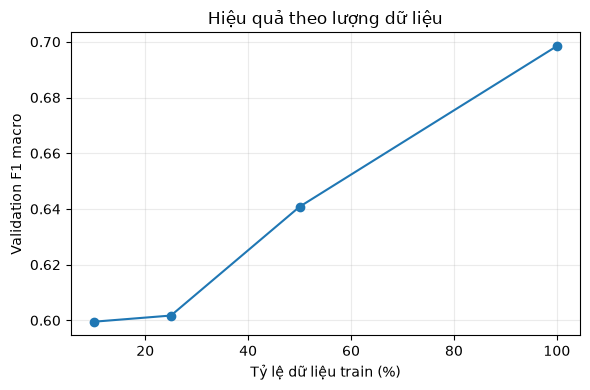

In [9]:
DATA_FRACTIONS = (0.10, 0.25, 0.50, 1.00)
subset_indices = stratified_nested_subsets(y_train, DATA_FRACTIONS, seed=RANDOM_SEED)
data_efficiency_summaries = {}

for fraction in DATA_FRACTIONS:
    if fraction == 1.0:
        run = fine_tuned_run
    else:
        indices = subset_indices[fraction]
        subset_encodings = {key: value[indices] for key, value in train_encodings.items()}
        run = train_one_model(
            pretrained=True, max_length=BASE_MAX_LENGTH,
            train_encodings_override=subset_encodings, labels_override=y_train[indices],
        )
    data_efficiency_summaries[fraction] = {
        'metrics': run['validation_result']['metrics'],
        'training_seconds': run['training_seconds'],
    }
    record_result(
        'Experiment 3 - Training data amount', f'BERT fine-tuned {fraction:.0%}',
        'validation', run['validation_result'], run, BASE_MAX_LENGTH, fraction,
    )
    if fraction < 1.0:
        del run, subset_encodings
        _ = gc.collect()

data_efficiency_table = pd.DataFrame([
    {'training_data_percent': int(fraction * 100), 'n_train': len(subset_indices[fraction]),
     'accuracy': data_efficiency_summaries[fraction]['metrics']['accuracy'],
     'f1_macro': data_efficiency_summaries[fraction]['metrics']['f1_macro'],
     'training_time_seconds': data_efficiency_summaries[fraction]['training_seconds']}
    for fraction in DATA_FRACTIONS
])
display(data_efficiency_table)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(data_efficiency_table['training_data_percent'], data_efficiency_table['f1_macro'], marker='o')
ax.set(xlabel='Tỷ lệ dữ liệu train (%)', ylabel='Validation F1 macro', title='Hiệu quả theo lượng dữ liệu')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(LAB_DIR / 'data_efficiency.png', dpi=160)
plt.show()

**Nhận xét Experiment 3:**

Validation macro F1 lần lượt là 0,5995 / 0,6017 / 0,6408 / 0,6985 khi dùng 10% / 25% / 50% / 100% train data. Điểm 10% và 25% khá gần nhau, sau đó tăng rõ hơn. Ở 10%, scratch đạt 0,3342 so với pretrained 0,5995.

## 10. Experiment 4 — Maximum sequence length

So sánh max_length 64/128/256 trên cùng subset phân tầng 25% của train split và cùng 2.000 ví dụ validation/test. Cấu hình này giới hạn bộ nhớ CPU; bảng ghi rõ số ví dụ.

C:\Users\KIEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 9990.10it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/1: train_loss=0.6764, validation_loss=0.6514, validation_f1_macro=0.6548


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

... (4 outputs left out)

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 38984.24it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/1: train_loss=0.6585, validation_loss=0.6076, validation_f1_macro=0.7181


,max_length,train_fraction,n_train,accuracy,f1_macro,training_time_seconds,peak_process_rss_mb,attention_scores_per_layer_per_example
0,64,0.25,7436,0.647,0.646957,47.322981,1078.484375,4096
1,128,0.25,7436,0.689,0.686790,95.193312,1026.222656,16384
2,256,0.25,7436,0.717,0.716346,214.037911,896.406250,65536


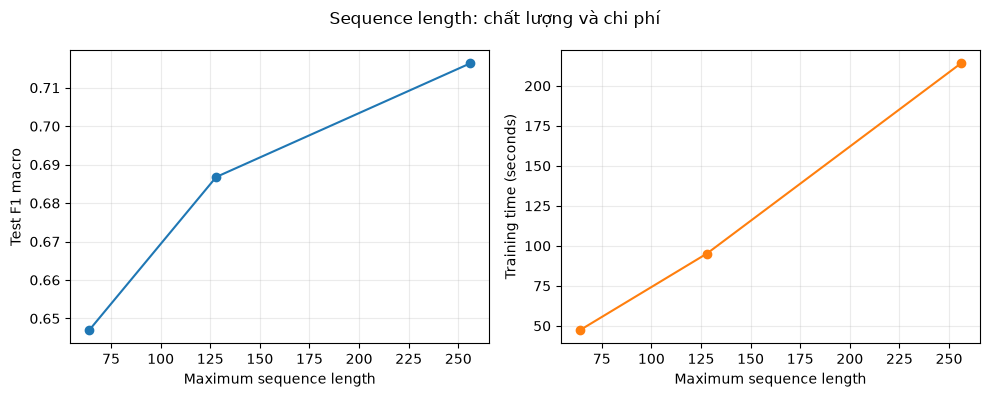

,evaluation_domain,n_examples,loss,accuracy,precision,recall,f1,f1_macro
0,IMDb movie reviews,2000,0.628558,0.689,0.664089,0.76992,0.713100,0.686790
1,Amazon product reviews,1000,0.633796,0.686,0.678161,0.70800,0.692759,0.685848


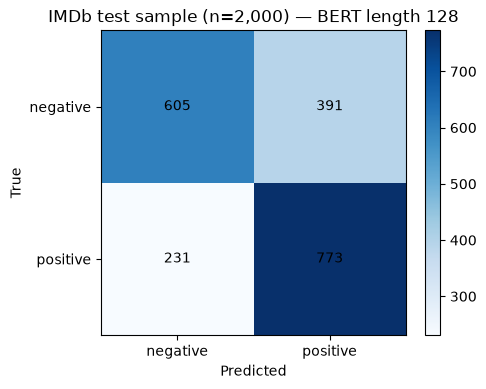

,band,n,accuracy,mean_confidence
0,Low (<0.70),2000.0,0.689,0.579042
1,Medium (0.70-0.90),NaN,NaN,NaN
2,High (>=0.90),NaN,NaN,NaN


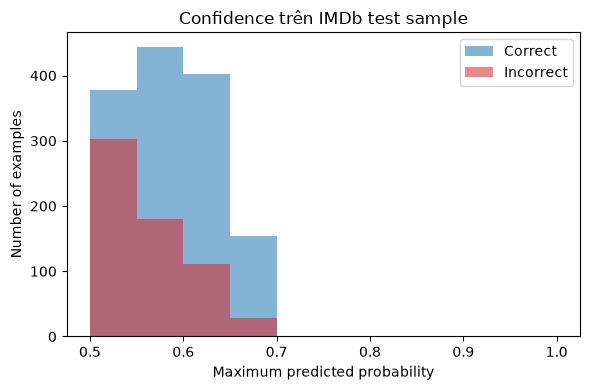

,error_group,true,predicted,confidence,review_excerpt
0,False positive,negative,positive,0.695138,Just watched on UbuWeb this early experimental...
1,False positive,negative,positive,0.682784,Stan Laurel and Oliver Hardy had extensive (se...
2,False positive,negative,positive,0.678474,Here is one of those educational short films m...
3,False negative,positive,negative,0.640594,"Okay, this wasn't the greatest horror movie I'..."
4,False negative,positive,negative,0.637809,black tar can't be snorted there's a documenta...
5,False negative,positive,negative,0.625037,"Somehow, this film burrowed it's way into the ..."


Số FP: 3 | số FN: 3 | confidence của 2 lỗi sai cao nhất: [0.6951000094413757, 0.6827999949455261]
Đã lưu results.csv với 13 dòng.


,experiment,model,split,train_fraction,max_length,n_train,n_evaluated,accuracy,f1_macro,training_time_seconds,parameters,trainable_parameters
0,Experiment 1 - Scratch vs pretrained,BERT from scratch,test,1.00,128,29746,9916,0.501916,0.334184,382.943282,4386178,4386178
1,Experiment 1 - Scratch vs pretrained,BERT fine-tuned,test,1.00,128,29746,9916,0.703308,0.695027,378.441199,4386178,4386178
2,Experiment 2 - Frozen vs fine-tuning,Frozen encoder,test,1.00,128,29746,9916,0.559197,0.555864,191.865392,4386178,258
3,Experiment 2 - Frozen vs fine-tuning,Fine-tuning all layers,test,1.00,128,29746,9916,0.703308,0.695027,378.441199,4386178,4386178
4,Experiment 3 - Training data amount,BERT fine-tuned 10%,validation,0.10,128,2975,9916,0.603772,0.599526,67.882744,4386178,4386178
5,Experiment 3 - Training data amount,BERT fine-tuned 25%,validation,0.25,128,7436,9916,0.618596,0.601740,121.906998,4386178,4386178
6,Experiment 3 - Training data amount,BERT fine-tuned 50%,validation,0.50,128,14873,9916,0.650867,0.640801,202.663860,4386178,4386178
7,Experiment 3 - Training data amount,BERT fine-tuned 100%,validation,1.00,128,29746,9916,0.706434,0.698455,378.441199,4386178,4386178
8,Experiment 4 - Maximum sequence length,BERT fine-tuned length 64,test sample,0.25,64,7436,2000,0.647000,0.646957,47.322981,4386178,4386178
9,Experiment 4 - Maximum sequence length,BERT fine-tuned length 128,test sample,0.25,128,7436,2000,0.689000,0.686790,95.193312,4386178,4386178


In [1]:
# Sweep có giới hạn để chạy trên CPU: cùng subset 25%, cùng validation/test sample.
import os
os.environ['OMP_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['TOKENIZERS_PARALLELISM']='false'
import gc, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from datasets import load_dataset

PROJECT_DIR=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data'/'IMDB Dataset.csv').exists()),None)
if PROJECT_DIR is None: raise FileNotFoundError('Không tìm thấy data/IMDB Dataset.csv.')
LAB_DIR=PROJECT_DIR/'lab08'; sys.path.insert(0,str(LAB_DIR))
from pretrained_classification import MODEL_NAME,RANDOM_SEED,build_model,encode_texts,evaluate_model,load_imdb,load_tokenizer,make_loader,set_seed,split_imdb,stratified_nested_subsets,train_model
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.get_num_threads()!=1: torch.set_num_threads(1)
if torch.get_num_interop_threads()!=1: torch.set_num_interop_threads(1)
torch.backends.mkldnn.enabled=False
MAX_TOKEN_LENGTH=256; LENGTHS=(64,128,256); TRAIN_FRACTION=0.25
BATCH_SIZE=32; EPOCHS=1; LEARNING_RATE=2e-5; EVAL_SIZE=2000

data,cleaning_stats=load_imdb(PROJECT_DIR/'data'/'IMDB Dataset.csv')
train_df,val_df,test_df=split_imdb(data,seed=RANDOM_SEED)
y_train=train_df.label_id.to_numpy(); y_val=val_df.label_id.to_numpy(); y_test=test_df.label_id.to_numpy()
subset_idx=stratified_nested_subsets(y_train,(TRAIN_FRACTION,),seed=RANDOM_SEED)[TRAIN_FRACTION]
_,val_idx=train_test_split(np.arange(len(val_df)),test_size=EVAL_SIZE,random_state=RANDOM_SEED,stratify=y_val)
_,test_idx=train_test_split(np.arange(len(test_df)),test_size=EVAL_SIZE,random_state=RANDOM_SEED,stratify=y_test)
train_texts=train_df.iloc[subset_idx].review.tolist(); train_labels=y_train[subset_idx]
val_texts=val_df.iloc[val_idx].review.tolist(); val_labels=y_val[val_idx]
test_texts=test_df.iloc[test_idx].review.tolist(); test_labels=y_test[test_idx]
del data,train_df,val_df,test_df; gc.collect()
tokenizer=load_tokenizer(MODEL_NAME)
train_enc=encode_texts(tokenizer,train_texts,MAX_TOKEN_LENGTH)
val_enc=encode_texts(tokenizer,val_texts,MAX_TOKEN_LENGTH)
test_enc=encode_texts(tokenizer,test_texts,MAX_TOKEN_LENGTH)
del train_texts,val_texts; gc.collect()

sequence_rows=[]; sequence_models={}
for length in LENGTHS:
    set_seed(RANDOM_SEED)
    model=build_model(MODEL_NAME,pretrained=True)
    train_loader=make_loader(train_enc,train_labels,length,BATCH_SIZE,True)
    val_loader=make_loader(val_enc,val_labels,length,BATCH_SIZE,False)
    test_loader=make_loader(test_enc,test_labels,length,BATCH_SIZE,False)
    run=train_model(model,train_loader,val_loader,DEVICE,epochs=EPOCHS,learning_rate=LEARNING_RATE)
    val_result=evaluate_model(run['model'],val_loader,DEVICE)
    test_result=evaluate_model(run['model'],test_loader,DEVICE)
    row={'experiment':'Experiment 4 - Maximum sequence length','model':f'BERT fine-tuned length {length}','split':'test sample','train_fraction':TRAIN_FRACTION,'max_length':length,'n_train':len(train_labels),'n_evaluated':len(test_labels),**test_result['metrics'],'training_time_seconds':run['training_seconds'],'parameters':run['parameters'],'trainable_parameters':run['trainable_parameters'],'peak_process_rss_mb':run['peak_rss_mb'],'epochs':EPOCHS,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE}
    sequence_rows.append(row)
    if length==128: sequence_models[128]={'run':run,'val':val_result,'test':test_result}
    else: del run,model
    del train_loader,val_loader,test_loader; gc.collect()

sequence_table=pd.DataFrame([{'max_length':r['max_length'],'train_fraction':r['train_fraction'],'n_train':r['n_train'],'accuracy':r['accuracy'],'f1_macro':r['f1_macro'],'training_time_seconds':r['training_time_seconds'],'peak_process_rss_mb':r['peak_process_rss_mb'],'attention_scores_per_layer_per_example':r['max_length']**2} for r in sequence_rows])
display(sequence_table)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(sequence_table.max_length,sequence_table.f1_macro,marker='o'); axes[0].set(xlabel='Maximum sequence length',ylabel='Test F1 macro')
axes[1].plot(sequence_table.max_length,sequence_table.training_time_seconds,marker='o',color='tab:orange'); axes[1].set(xlabel='Maximum sequence length',ylabel='Training time (seconds)')
for ax in axes: ax.grid(alpha=.25)
fig.suptitle('Sequence length: chất lượng và chi phí'); fig.tight_layout(); fig.savefig(LAB_DIR/'sequence_length.png',dpi=160); plt.show()

# IMDb -> Amazon product reviews: mẫu cân bằng 500 review mỗi lớp.
amazon=load_dataset('fancyzhx/amazon_polarity',split='test[:2000]')
amazon_df=pd.DataFrame(amazon)
amazon_df['review']=(amazon_df.title.fillna('').astype(str)+'. '+amazon_df.content.fillna('').astype(str)).str.strip()
label_names=amazon.features['label'].names
amazon_df['label_text']=amazon_df.label.map({i:name for i,name in enumerate(label_names)})
amazon_df=amazon_df[amazon_df.label_text.isin(['negative','positive'])].copy()
amazon_df['label_id']=amazon_df.label_text.map({'negative':0,'positive':1}).astype(int)
per_class=int(min(500,amazon_df.label_id.value_counts().min()))
amazon_sample=amazon_df.groupby('label_id',group_keys=False).sample(n=per_class,random_state=RANDOM_SEED).reset_index(drop=True)
amazon_enc=encode_texts(tokenizer,amazon_sample.review,MAX_TOKEN_LENGTH)
amazon_loader=make_loader(amazon_enc,amazon_sample.label_id,128,BATCH_SIZE,False)
selected_run=sequence_models[128]['run']; in_domain=sequence_models[128]['test']
amazon_result=evaluate_model(selected_run['model'],amazon_loader,DEVICE)
domain_table=pd.DataFrame([{'evaluation_domain':'IMDb movie reviews','n_examples':len(test_labels),**in_domain['metrics']},{'evaluation_domain':'Amazon product reviews','n_examples':len(amazon_sample),**amazon_result['metrics']}])
display(domain_table)

# Confusion matrix và confidence trên cùng test sample IMDb n=2,000.
selected=in_domain; probs=selected['probabilities']; conf=probs.max(axis=1); correct=selected['predictions']==selected['targets']
cm=confusion_matrix(selected['targets'],selected['predictions'],labels=[0,1])
fig,ax=plt.subplots(figsize=(5,4)); im=ax.imshow(cm,cmap='Blues')
for (i,j),v in np.ndenumerate(cm): ax.text(j,i,f'{v:,}',ha='center',va='center')
ax.set_xticks([0,1],labels=['negative','positive']); ax.set_yticks([0,1],labels=['negative','positive'])
ax.set(xlabel='Predicted',ylabel='True',title='IMDb test sample (n=2,000) — BERT length 128')
fig.colorbar(im,ax=ax); fig.tight_layout(); fig.savefig(LAB_DIR/'confusion_matrix.png',dpi=160); plt.show()
band=np.where(conf>=.90,'High (>=0.90)',np.where(conf>=.70,'Medium (0.70-0.90)','Low (<0.70)'))
confidence_df=pd.DataFrame({'band':band,'confidence':conf,'correct':correct})
confidence_table=confidence_df.groupby('band').agg(n=('correct','size'),accuracy=('correct','mean'),mean_confidence=('confidence','mean')).reindex(['Low (<0.70)','Medium (0.70-0.90)','High (>=0.90)']).reset_index()
display(confidence_table)
fig,ax=plt.subplots(figsize=(6,4))
for ok,label,color in [(True,'Correct','tab:blue'),(False,'Incorrect','tab:red')]: ax.hist(conf[correct==ok],bins=np.linspace(.5,1,11),alpha=.55,label=label,color=color)
ax.set(xlabel='Maximum predicted probability',ylabel='Number of examples',title='Confidence trên IMDb test sample'); ax.legend(); fig.tight_layout(); fig.savefig(LAB_DIR/'confidence_analysis.png',dpi=160); plt.show()

error_frame=pd.DataFrame({'review':test_texts,'true':selected['targets'],'predicted':selected['predictions'],'confidence':conf,'p_positive':probs[:,1],'correct':correct})
false_pos=error_frame[(error_frame.true==0)&(error_frame.predicted==1)].sort_values('confidence',ascending=False).head(3).copy()
false_neg=error_frame[(error_frame.true==1)&(error_frame.predicted==0)].sort_values('confidence',ascending=False).head(3).copy()
most_confident=error_frame[~error_frame.correct].sort_values('confidence',ascending=False).head(2).copy()
false_pos['error_group']='False positive'; false_neg['error_group']='False negative'; most_confident['error_group']='Hai lỗi sai có confidence cao nhất'
error_candidates=pd.concat([false_pos,false_neg,most_confident]).drop_duplicates(subset='review').reset_index(drop=True)
error_candidates['true']=error_candidates.true.map({0:'negative',1:'positive'}); error_candidates['predicted']=error_candidates.predicted.map({0:'negative',1:'positive'})
error_candidates['review_excerpt']=error_candidates.review.str.slice(0,500)
display(error_candidates[['error_group','true','predicted','confidence','review_excerpt']])
print('Số FP:',len(false_pos),'| số FN:',len(false_neg),'| confidence của 2 lỗi sai cao nhất:',most_confident.confidence.round(4).tolist())

if isinstance(globals().get('RESULT_ROWS'),list) and RESULT_ROWS: base=pd.DataFrame(RESULT_ROWS)
else: base=pd.read_csv(LAB_DIR/'results.csv')
base=base[~base.experiment.astype(str).str.startswith(('Experiment 4 -','Experiment 5 -'))].copy()
new_rows=sequence_rows+[
 {'experiment':'Experiment 5 - Domain shift','model':'IMDb fine-tuned 25% -> IMDb','split':'IMDb test sample','train_fraction':TRAIN_FRACTION,'max_length':128,'n_train':len(train_labels),'n_evaluated':len(test_labels),**in_domain['metrics'],'training_time_seconds':selected_run['training_seconds'],'parameters':selected_run['parameters'],'trainable_parameters':selected_run['trainable_parameters'],'peak_process_rss_mb':selected_run['peak_rss_mb'],'epochs':EPOCHS,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE},
 {'experiment':'Experiment 5 - Domain shift','model':'IMDb fine-tuned 25% -> Amazon','split':'Amazon product test sample','train_fraction':TRAIN_FRACTION,'max_length':128,'n_train':len(train_labels),'n_evaluated':len(amazon_sample),**amazon_result['metrics'],'training_time_seconds':selected_run['training_seconds'],'parameters':selected_run['parameters'],'trainable_parameters':selected_run['trainable_parameters'],'peak_process_rss_mb':selected_run['peak_rss_mb'],'epochs':EPOCHS,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE},
]
if 'n_train' not in base: base['n_train']=np.where(base.experiment.astype(str).str.contains('Training data amount'),(base.train_fraction*29746).round(),29746)
if 'n_evaluated' not in base: base['n_evaluated']=9916
results=pd.concat([base,pd.DataFrame(new_rows)],ignore_index=True,sort=False)
results.to_csv(LAB_DIR/'results.csv',index=False,encoding='utf-8-sig')
if isinstance(globals().get('RESULT_ROWS'),list): RESULT_ROWS[:]=base.to_dict('records')+new_rows
else: RESULT_ROWS=base.to_dict('records')+new_rows
print('Đã lưu results.csv với',len(results),'dòng.'); display(results[['experiment','model','split','train_fraction','max_length','n_train','n_evaluated','accuracy','f1_macro','training_time_seconds','parameters','trainable_parameters']])

**Nhận xét Experiment 4:**

Trên cùng 7.436 review train và 2.000 review test, macro F1 tăng 0,6470 → 0,6868 → 0,7163 khi max_length tăng 64 → 128 → 256. Thời gian train tăng 47,3 → 95,2 → 214,0 giây; số cặp attention mỗi layer tăng theo T².

Cell sweep có in thêm kết quả preview một epoch cho domain/confidence; phần phân tích cuối dùng classifier ứng dụng ba epoch ở cell sau.

## 11. Experiment 5 — Domain shift: IMDb sang Amazon Polarity

Model fine-tune trên movie reviews IMDb, test trên product reviews Amazon.

## 12. Application — BERT fine-tuned 3 epochs

Để phân tích confidence và ví dụ lỗi, train thêm một classifier 3 epoch trên cùng subset phân tầng 25%; test IMDb và Amazon được giữ cố định.

C:\Users\KIEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/39 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 39/39 [00:00<00:00, 19308.06it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-2_H-128_A-2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3: train_loss=0.6671, validation_loss=0.6315, validation_f1_macro=0.6791


Epoch 2/3: train_loss=0.5916, validation_loss=0.5515, validation_f1_macro=0.7169


Epoch 3/3: train_loss=0.4938, validation_loss=0.4541, validation_f1_macro=0.7978


,model,epochs,train_fraction,n_train,n_test,loss,accuracy,precision,recall,f1,f1_macro,training_time_seconds,parameters
0,google/bert_uncased_L-2_H-128_A-2,3,0.25,7436,2000,0.463622,0.783,0.81808,0.73008,0.771579,0.782456,272.951462,4386178


,domain,n_examples,loss,accuracy,precision,recall,f1,f1_macro
0,IMDb movie reviews,2000,0.463622,0.783,0.818080,0.73008,0.771579,0.782456
1,Amazon product reviews,1000,0.475138,0.774,0.746403,0.83000,0.785985,0.773289


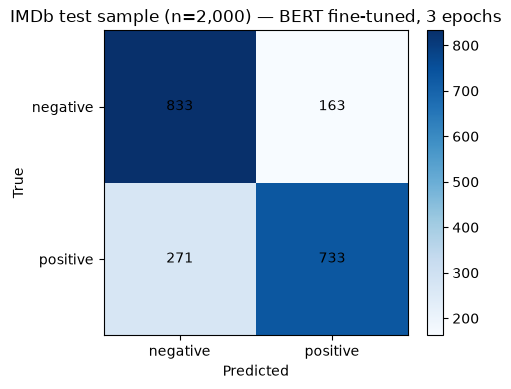

,band,n,accuracy,mean_confidence
0,Low (<0.70),430,0.569767,0.599581
1,Medium (0.70-0.90),1467,0.833674,0.834363
2,High (>=0.90),103,0.951456,0.904596


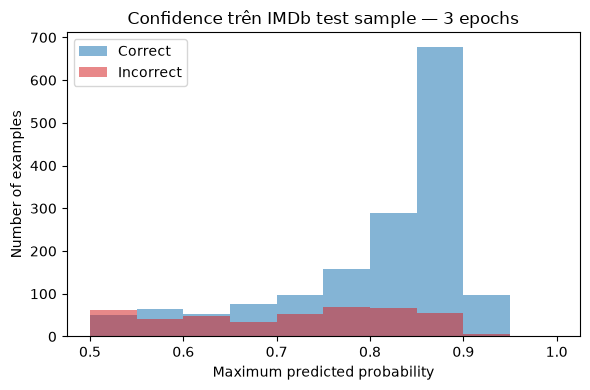

,error_group,true,predicted,confidence,review_excerpt
0,False positive,negative,positive,0.884830,I hadn't heard of this film until I read an ar...
1,False positive,negative,positive,0.882946,Just watched on UbuWeb this early experimental...
2,False positive,negative,positive,0.879139,Stan Laurel and Oliver Hardy had extensive (se...
3,False negative,positive,negative,0.902865,black tar can't be snorted there's a documenta...
4,False negative,positive,negative,0.900952,A horror movie is being shot and things aren't...
5,False negative,positive,negative,0.900510,"maybe i need to have my head examined,but i th..."


Số FP: 3 | số FN: 3 | confidence của 2 lỗi sai cao nhất: [0.902899980545044, 0.9010000228881836]


,experiment,model,split,n_train,n_evaluated,accuracy,f1_macro,training_time_seconds,epochs
8,Experiment 4 - Maximum sequence length,BERT fine-tuned length 64,test sample,7436,2000,0.647,0.646957,47.322981,1
9,Experiment 4 - Maximum sequence length,BERT fine-tuned length 128,test sample,7436,2000,0.689,0.686790,95.193312,1
10,Experiment 4 - Maximum sequence length,BERT fine-tuned length 256,test sample,7436,2000,0.717,0.716346,214.037911,1
11,Experiment 5 - Domain shift,IMDb fine-tuned 25% (3 epochs) -> IMDb,IMDb test sample,7436,2000,0.783,0.782456,272.951462,3
12,Experiment 5 - Domain shift,IMDb fine-tuned 25% (3 epochs) -> Amazon,Amazon test sample,7436,1000,0.774,0.773289,272.951462,3


In [1]:
# Model ứng dụng 3 epoch để lấy đủ confidence/error examples cho phần phân tích.
import os
os.environ['OMP_NUM_THREADS']='1'; os.environ['MKL_NUM_THREADS']='1'; os.environ['OPENBLAS_NUM_THREADS']='1'; os.environ['TOKENIZERS_PARALLELISM']='false'
import gc,sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from datasets import load_dataset

# Nếu notebook chạy từ đầu, giải phóng các model của sequence sweep trước model cuối.
for name in ('sequence_models','selected_run','train_enc','val_enc','test_enc','amazon_enc','amazon_loader'):
    globals().pop(name,None)
gc.collect()
PROJECT_DIR=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data'/'IMDB Dataset.csv').exists()),None)
if PROJECT_DIR is None: raise FileNotFoundError('Không tìm thấy data/IMDB Dataset.csv.')
LAB_DIR=PROJECT_DIR/'lab08'; sys.path.insert(0,str(LAB_DIR))
from pretrained_classification import MODEL_NAME,RANDOM_SEED,build_model,encode_texts,evaluate_model,load_imdb,load_tokenizer,make_loader,set_seed,split_imdb,stratified_nested_subsets,train_model
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.get_num_threads()!=1: torch.set_num_threads(1)
if torch.get_num_interop_threads()!=1: torch.set_num_interop_threads(1)
torch.backends.mkldnn.enabled=False
MAX_LENGTH=128; MAX_TOKEN_LENGTH=256; TRAIN_FRACTION=0.25; BATCH_SIZE=32; EPOCHS=3; LEARNING_RATE=2e-5; EVAL_SIZE=2000

data,stats=load_imdb(PROJECT_DIR/'data'/'IMDB Dataset.csv')
train_df,val_df,test_df=split_imdb(data,seed=RANDOM_SEED)
y_train=train_df.label_id.to_numpy(); y_val=val_df.label_id.to_numpy(); y_test=test_df.label_id.to_numpy()
indices=stratified_nested_subsets(y_train,(TRAIN_FRACTION,),seed=RANDOM_SEED)[TRAIN_FRACTION]
_,val_idx=train_test_split(np.arange(len(val_df)),test_size=EVAL_SIZE,random_state=RANDOM_SEED,stratify=y_val)
_,test_idx=train_test_split(np.arange(len(test_df)),test_size=EVAL_SIZE,random_state=RANDOM_SEED,stratify=y_test)
train_texts=train_df.iloc[indices].review.tolist(); train_labels=y_train[indices]
val_texts=val_df.iloc[val_idx].review.tolist(); val_labels=y_val[val_idx]
test_texts=test_df.iloc[test_idx].review.tolist(); test_labels=y_test[test_idx]
del data,train_df,val_df,test_df; gc.collect()
tokenizer=load_tokenizer(MODEL_NAME)
train_enc=encode_texts(tokenizer,train_texts,MAX_TOKEN_LENGTH)
val_enc=encode_texts(tokenizer,val_texts,MAX_TOKEN_LENGTH)
test_enc=encode_texts(tokenizer,test_texts,MAX_TOKEN_LENGTH)
del train_texts,val_texts; gc.collect()
set_seed(RANDOM_SEED); model=build_model(MODEL_NAME,pretrained=True)
train_loader=make_loader(train_enc,train_labels,MAX_LENGTH,BATCH_SIZE,True)
val_loader=make_loader(val_enc,val_labels,MAX_LENGTH,BATCH_SIZE,False)
test_loader=make_loader(test_enc,test_labels,MAX_LENGTH,BATCH_SIZE,False)
application_run=train_model(model,train_loader,val_loader,DEVICE,epochs=EPOCHS,learning_rate=LEARNING_RATE)
application_result=evaluate_model(application_run['model'],test_loader,DEVICE)
application_table=pd.DataFrame([{'model':MODEL_NAME,'epochs':EPOCHS,'train_fraction':TRAIN_FRACTION,'n_train':len(train_labels),'n_test':len(test_labels),**application_result['metrics'],'training_time_seconds':application_run['training_seconds'],'parameters':application_run['parameters']}])
display(application_table)

# Chạy cùng classifier trên Amazon product reviews để kiểm tra chuyển domain.
amazon=load_dataset('fancyzhx/amazon_polarity',split='test[:2000]')
amazon_df=pd.DataFrame(amazon)
amazon_df['review']=(amazon_df.title.fillna('').astype(str)+'. '+amazon_df.content.fillna('').astype(str)).str.strip()
label_names=amazon.features['label'].names
amazon_df['label_text']=amazon_df.label.map({i:name for i,name in enumerate(label_names)})
amazon_df=amazon_df[amazon_df.label_text.isin(['negative','positive'])].copy()
amazon_df['label_id']=amazon_df.label_text.map({'negative':0,'positive':1}).astype(int)
per_class=int(min(500,amazon_df.label_id.value_counts().min()))
amazon_sample=amazon_df.groupby('label_id',group_keys=False).sample(n=per_class,random_state=RANDOM_SEED).reset_index(drop=True)
amazon_enc=encode_texts(tokenizer,amazon_sample.review,MAX_TOKEN_LENGTH)
amazon_loader=make_loader(amazon_enc,amazon_sample.label_id,MAX_LENGTH,BATCH_SIZE,False)
amazon_result=evaluate_model(application_run['model'],amazon_loader,DEVICE)
domain_table=pd.DataFrame([{'domain':'IMDb movie reviews','n_examples':len(test_labels),**application_result['metrics']},{'domain':'Amazon product reviews','n_examples':len(amazon_sample),**amazon_result['metrics']}])
display(domain_table)

# Confusion matrix và confidence cho model ứng dụng 3 epoch.
probs=application_result['probabilities']; confidence=probs.max(axis=1); correct=application_result['predictions']==application_result['targets']
cm=confusion_matrix(application_result['targets'],application_result['predictions'],labels=[0,1])
fig,ax=plt.subplots(figsize=(5,4)); im=ax.imshow(cm,cmap='Blues')
for (i,j),v in np.ndenumerate(cm): ax.text(j,i,f'{v:,}',ha='center',va='center')
ax.set_xticks([0,1],labels=['negative','positive']); ax.set_yticks([0,1],labels=['negative','positive'])
ax.set(xlabel='Predicted',ylabel='True',title='IMDb test sample (n=2,000) — BERT fine-tuned, 3 epochs')
fig.colorbar(im,ax=ax); fig.tight_layout(); fig.savefig(LAB_DIR/'confusion_matrix.png',dpi=160); plt.show()
band=np.where(confidence>=.90,'High (>=0.90)',np.where(confidence>=.70,'Medium (0.70-0.90)','Low (<0.70)'))
confidence_table=pd.DataFrame({'band':band,'confidence':confidence,'correct':correct}).groupby('band').agg(n=('correct','size'),accuracy=('correct','mean'),mean_confidence=('confidence','mean')).reindex(['Low (<0.70)','Medium (0.70-0.90)','High (>=0.90)']).reset_index()
display(confidence_table)
fig,ax=plt.subplots(figsize=(6,4))
for ok,label,color in [(True,'Correct','tab:blue'),(False,'Incorrect','tab:red')]: ax.hist(confidence[correct==ok],bins=np.linspace(.5,1,11),alpha=.55,label=label,color=color)
ax.set(xlabel='Maximum predicted probability',ylabel='Number of examples',title='Confidence trên IMDb test sample — 3 epochs'); ax.legend(); fig.tight_layout(); fig.savefig(LAB_DIR/'confidence_analysis.png',dpi=160); plt.show()

error_frame=pd.DataFrame({'review':test_texts,'true':application_result['targets'],'predicted':application_result['predictions'],'confidence':confidence,'p_positive':probs[:,1],'correct':correct})
false_pos=error_frame[(error_frame.true==0)&(error_frame.predicted==1)].sort_values('confidence',ascending=False).head(3).copy()
false_neg=error_frame[(error_frame.true==1)&(error_frame.predicted==0)].sort_values('confidence',ascending=False).head(3).copy()
confident_errors=error_frame[~error_frame.correct].sort_values('confidence',ascending=False).head(2).copy()
false_pos['error_group']='False positive'; false_neg['error_group']='False negative'; confident_errors['error_group']='Hai lỗi sai có confidence cao nhất'
error_candidates=pd.concat([false_pos,false_neg,confident_errors]).drop_duplicates(subset='review').reset_index(drop=True)
error_candidates['true']=error_candidates.true.map({0:'negative',1:'positive'}); error_candidates['predicted']=error_candidates.predicted.map({0:'negative',1:'positive'})
error_candidates['review_excerpt']=error_candidates.review.str.slice(0,500)
display(error_candidates[['error_group','true','predicted','confidence','review_excerpt']])
print('Số FP:',len(false_pos),'| số FN:',len(false_neg),'| confidence của 2 lỗi sai cao nhất:',confident_errors.confidence.round(4).tolist())

# Thay các dòng domain shift 1 epoch bằng kết quả model ứng dụng 3 epoch.
results=pd.read_csv(LAB_DIR/'results.csv')
results=results[~results.experiment.astype(str).str.startswith('Experiment 5 -')].copy()
new_rows=[]
for domain,result,n in [('IMDb',application_result,len(test_labels)),('Amazon',amazon_result,len(amazon_sample))]:
    new_rows.append({'experiment':'Experiment 5 - Domain shift','model':f'IMDb fine-tuned 25% (3 epochs) -> {domain}','split':f'{domain} test sample','train_fraction':TRAIN_FRACTION,'max_length':MAX_LENGTH,'n_train':len(train_labels),'n_evaluated':n,**result['metrics'],'training_time_seconds':application_run['training_seconds'],'parameters':application_run['parameters'],'trainable_parameters':application_run['trainable_parameters'],'peak_process_rss_mb':application_run['peak_rss_mb'],'epochs':EPOCHS,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE})
results=pd.concat([results,pd.DataFrame(new_rows)],ignore_index=True,sort=False)
results.to_csv(LAB_DIR/'results.csv',index=False,encoding='utf-8-sig')
display(results.tail(5)[['experiment','model','split','n_train','n_evaluated','accuracy','f1_macro','training_time_seconds','epochs']])

## 13. Prediction 3 — scratch và pretrained với 10% train data

Chạy cùng 10% train subset, tokenizer, max_length, validation split, batch size và epoch để so sánh trực tiếp.

C:\Users\KIEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Epoch 1/1: train_loss=0.6935, validation_loss=0.6932, validation_f1_macro=0.3342


,model,n_train,accuracy,f1_macro,loss,training_time_seconds
0,BERT from scratch 10%,2975,0.501916,0.334184,0.693156,41.228564
1,BERT fine-tuned 10%,2975,0.603772,0.599526,NaN,67.882744


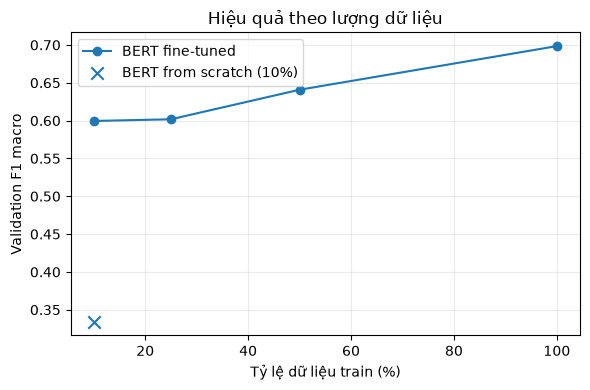

,model,train_fraction,n_train,accuracy,f1_macro,training_time_seconds
4,BERT fine-tuned 10%,0.10,2975,0.603772,0.599526,67.882744
5,BERT fine-tuned 25%,0.25,7436,0.618596,0.601740,121.906998
6,BERT fine-tuned 50%,0.50,14873,0.650867,0.640801,202.663860
7,BERT fine-tuned 100%,1.00,29746,0.706434,0.698455,378.441199
13,BERT from scratch 10%,0.10,2975,0.501916,0.334184,41.228564


In [1]:
# So sánh thêm scratch ở 10% để trả lời trực tiếp Prediction 3.
import os
os.environ['OMP_NUM_THREADS']='1'; os.environ['MKL_NUM_THREADS']='1'; os.environ['OPENBLAS_NUM_THREADS']='1'; os.environ['TOKENIZERS_PARALLELISM']='false'
import gc,sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.model_selection import train_test_split

PROJECT_DIR=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data'/'IMDB Dataset.csv').exists()),None)
if PROJECT_DIR is None: raise FileNotFoundError('Không tìm thấy data/IMDB Dataset.csv.')
LAB_DIR=PROJECT_DIR/'lab08'; sys.path.insert(0,str(LAB_DIR))
from pretrained_classification import MODEL_NAME,RANDOM_SEED,build_model,encode_texts,load_imdb,load_tokenizer,make_loader,set_seed,split_imdb,stratified_nested_subsets,train_model
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.get_num_threads()!=1: torch.set_num_threads(1)
if torch.get_num_interop_threads()!=1: torch.set_num_interop_threads(1)
torch.backends.mkldnn.enabled=False
MAX_LENGTH=128; BATCH_SIZE=128; LEARNING_RATE=2e-5; EPOCHS=1; FRACTION=0.10

data,_=load_imdb(PROJECT_DIR/'data'/'IMDB Dataset.csv')
train_df,val_df,_=split_imdb(data,seed=RANDOM_SEED)
y_train=train_df.label_id.to_numpy(); y_val=val_df.label_id.to_numpy()
indices=stratified_nested_subsets(y_train,(FRACTION,),seed=RANDOM_SEED)[FRACTION]
tokenizer=load_tokenizer(MODEL_NAME)
train_enc=encode_texts(tokenizer,train_df.iloc[indices].review,MAX_LENGTH)
val_enc=encode_texts(tokenizer,val_df.review,MAX_LENGTH)
train_labels=y_train[indices]
train_loader=make_loader(train_enc,train_labels,MAX_LENGTH,BATCH_SIZE,True)
val_loader=make_loader(val_enc,y_val,MAX_LENGTH,BATCH_SIZE,False)
set_seed(RANDOM_SEED); model=build_model(MODEL_NAME,pretrained=False)
scratch10_run=train_model(model,train_loader,val_loader,DEVICE,epochs=EPOCHS,learning_rate=LEARNING_RATE)
val_row=scratch10_run['history'].iloc[-1]
scratch10_metrics={'accuracy':val_row['validation_accuracy'],'f1_macro':val_row['validation_f1_macro'],'loss':val_row['validation_loss']}
results=pd.read_csv(LAB_DIR/'results.csv')
results=results[~((results.experiment=='Experiment 3 - Training data amount')&(results.model=='BERT from scratch 10%'))].copy()
pretrained10=results[(results.experiment=='Experiment 3 - Training data amount')&(results.model=='BERT fine-tuned 10%')].iloc[0]
new_row={'experiment':'Experiment 3 - Training data amount','model':'BERT from scratch 10%','split':'validation','train_fraction':FRACTION,'max_length':MAX_LENGTH,'n_train':len(train_labels),'n_evaluated':len(val_df),'accuracy':scratch10_metrics['accuracy'],'f1_macro':scratch10_metrics['f1_macro'],'loss':scratch10_metrics['loss'],'training_time_seconds':scratch10_run['training_seconds'],'parameters':scratch10_run['parameters'],'trainable_parameters':scratch10_run['trainable_parameters'],'peak_process_rss_mb':scratch10_run['peak_rss_mb'],'epochs':EPOCHS,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE}
results=pd.concat([results,pd.DataFrame([new_row])],ignore_index=True,sort=False)
results.to_csv(LAB_DIR/'results.csv',index=False,encoding='utf-8-sig')
comparison=pd.DataFrame([
 {'model':'BERT from scratch 10%','n_train':len(train_labels),**scratch10_metrics,'training_time_seconds':scratch10_run['training_seconds']},
 {'model':'BERT fine-tuned 10%','n_train':int(pretrained10.n_train),'accuracy':pretrained10.accuracy,'f1_macro':pretrained10.f1_macro,'loss':pretrained10.loss,'training_time_seconds':pretrained10.training_time_seconds},
])
display(comparison)

# Cập nhật biểu đồ data efficiency để có điểm đối chiếu scratch tại 10%.
pretrained_curve=results[(results.experiment=='Experiment 3 - Training data amount')&results.model.str.startswith('BERT fine-tuned')].sort_values('train_fraction')
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(pretrained_curve.train_fraction*100,pretrained_curve.f1_macro,marker='o',label='BERT fine-tuned')
ax.scatter([10],[scratch10_metrics['f1_macro']],marker='x',s=80,label='BERT from scratch (10%)')
ax.set(xlabel='Tỷ lệ dữ liệu train (%)',ylabel='Validation F1 macro',title='Hiệu quả theo lượng dữ liệu')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(LAB_DIR/'data_efficiency.png',dpi=160); plt.show()
display(results[results.experiment=='Experiment 3 - Training data amount'][['model','train_fraction','n_train','accuracy','f1_macro','training_time_seconds']])

**Nhận xét Experiment 5:**

Model 3 epoch đạt IMDb macro F1 0,7825 và Amazon macro F1 0,7733; accuracy lần lượt 0,783 và 0,774. Trong hai sample này mức giảm nhỏ, nhưng Amazon chỉ có 1.000 review nên kết quả chưa đại diện cho mọi domain.

## 14. Confusion matrix và Confidence Analysis

Các cell phía trên lưu hai biểu đồ và bảng confidence trên cùng IMDb test sample.

**Nhận xét Confidence Analysis:**

Trong nhóm confidence >=0,90 có 103 dự đoán, accuracy 0,9515; nhóm này vẫn có 5 lỗi. Hai lỗi sai có confidence cao nhất là 0,9029 và 0,9010, nên confidence cao không bảo đảm nhãn đúng.

## 15. Error analysis

Các ví dụ 3 false positives, 3 false negatives và confidence được in ở cell Application 3 epochs phía trên; phân loại lỗi và giả thuyết nằm trong error_analysis.md.

## 16. Nhận xét tổng kết theo kết quả chạy

- **Experiment 1:** Pretrained vượt scratch rõ trong lần chạy một epoch.
- **Experiment 2:** Fine-tuning cải thiện so với frozen nhưng tăng thời gian và số tham số cập nhật.
- **Experiment 3:** F1 tăng theo lượng train data; so sánh 10% xác nhận pretrained giữ kết quả tốt hơn scratch.
- **Experiment 4:** Sequence dài hơn tăng F1 trên sample này nhưng làm thời gian train tăng.
- **Experiment 5:** IMDb và Amazon có macro F1 gần nhau trong các sample đã dùng.
- **Confidence / error analysis:** Nhóm confidence cao chính xác hơn, song vẫn có các lỗi phủ định/ngữ cảnh với confidence >0,90.